# Experiment 009: A100-only comparison of all current model scales

This notebook compares the completed 0.5B, 1.5B and 3B Qwen models using only
runs with recorded A100 provenance. The frozen SFT-to-GRPO route is the primary
three-scale comparison. Base-GRPO and matched-exposure MC-SFT controls are shown
separately because they currently exist only for 0.5B and 3B.

A100 40GB and A100 80GB are both included. They are the same GPU family. The T4 runs from experiments 001 and 002 are excluded.


In [15]:
# load the A100 model results and retag every row with the validated tiers
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "config.py").exists():
    raise FileNotFoundError("repository root containing config.py was not found")
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows, paired_delta_ci
from data.subjects import TIERS as VALIDATED_TIERS, TIERS_PROPOSAL, all_subjects

RES = ROOT / "results"
FIG = ROOT / "analysis" / "figures" / "009_2"
FIG.mkdir(parents=True, exist_ok=True)

SCALES = ["0.5B", "1.5B", "3B"]
PARAMS = {"0.5B": 0.5, "1.5B": 1.5, "3B": 3.0}
TIERS = ["easy", "medium", "hard"]
GROUPS = TIERS + ["overall"]
CONDITIONS = ["base", "sft", "grpo"]
CONDITION_LABELS = {"base": "base", "sft": "SFT", "grpo": "SFT + GRPO"}
COLORS = {"base": "#4C78A8", "sft": "#54A24B", "grpo": "#F58518", "probe": "#B279A2"}
TIER_COLORS = {"easy": "#59A14F", "medium": "#F28E2B", "hard": "#E15759", "overall": "#333333"}
SEED_COLORS = {0: "#4C78A8", 1: "#F58518", 2: "#54A24B"}
SEED_MARKERS = {0: "o", 1: "s", 2: "^"}
TIER_LOOKUP = {subject: tier for tier, subjects in VALIDATED_TIERS.items() for subject in subjects}

CORE = {
    "0.5B": {
        "seeds": (0, 1, 2),
        "runs": {seed: RES / f"006_COLAB_FULL_B05_sft_grpo_seed{seed}" for seed in (0, 1, 2)},
        "base": RES / "base_evals" / "006_COLAB_FULL_B05",
    },
    "1.5B": {
        "seeds": (0, 1),
        "runs": {seed: RES / f"009_COLAB_FULL_B15_sft_grpo_seed{seed}" for seed in (0, 1)},
        "base": RES / "base_evals" / "009_COLAB_FULL_B15",
    },
    "3B": {
        "seeds": (0, 1),
        "runs": {seed: RES / f"003_COLAB_FULL_B3_sft_grpo_seed{seed}" for seed in (0, 1)},
        "base": RES / "base_evals" / "003_COLAB_FULL_B3",
    },
}

CORE_CONFIGS = {
    "0.5B": {seed: ROOT / f"configs/006_colab_full_b05_seed{seed}.yaml" for seed in (0, 1, 2)},
    "1.5B": {seed: ROOT / f"configs/009_colab_full_b15_seed{seed}.yaml" for seed in (0, 1)},
    "3B": {seed: ROOT / f"configs/003_colab_full_b3_seed{seed}.yaml" for seed in (0, 1)},
}

CONTROL_SPECS = {
    "0.5B": {
        "base GRPO": {0: (RES / "005_COLAB_FULL_B05_base_grpo_seed0", "grpo")},
        "warm GRPO": {seed: (CORE["0.5B"]["runs"][seed], "grpo") for seed in CORE["0.5B"]["seeds"]},
        "base MC-SFT": {seed: (RES / f"007_p8_COLAB_FULL_B05_sft_only_seed{seed}", "sft") for seed in (0, 1, 2)},
        "warm MC-SFT": {seed: (RES / f"008_wsft_COLAB_FULL_B05_sft_only_seed{seed}", "sft") for seed in (0, 1, 2)},
    },
    "1.5B": {
        "warm GRPO": {seed: (CORE["1.5B"]["runs"][seed], "grpo") for seed in CORE["1.5B"]["seeds"]},
    },
    "3B": {
        "base GRPO": {0: (RES / "004_COLAB_FULL_B3_base_grpo_seed0", "grpo")},
        "warm GRPO": {seed: (CORE["3B"]["runs"][seed], "grpo") for seed in CORE["3B"]["seeds"]},
        "base MC-SFT": {seed: (RES / f"007_p8_COLAB_FULL_B3_sft_only_seed{seed}", "sft") for seed in (0, 1, 2)},
        "warm MC-SFT": {seed: (RES / f"008_wsft_COLAB_FULL_B3_sft_only_seed{seed}", "sft") for seed in (0, 1, 2)},
    },
}

plt.style.use("seaborn-v0_8-whitegrid")

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def yload(path):
    with open(path) as handle:
        return yaml.safe_load(handle)

def rows(path):
    with open(path) as handle:
        data = [json.loads(line) for line in handle if line.strip()]
    return [{**row, "tier": TIER_LOOKUP[row["subject"]]} for row in data]

def accuracy(data):
    return float(np.mean([bool(row["correct"]) for row in data]))

def grouped(data, group, tiers=VALIDATED_TIERS):
    if group == "overall":
        return data
    subjects = set(tiers[group])
    return [row for row in data if row["subject"] in subjects]

def group_accuracy(data, group, tiers=VALIDATED_TIERS):
    return accuracy(grouped(data, group, tiers))

def subject_accuracy(data):
    return {
        subject: accuracy([row for row in data if row["subject"] == subject])
        for subject in all_subjects()
    }

def item_keys(data):
    return [(row["subject"], row["gold"]) for row in data]

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

def load_core(scale):
    info = CORE[scale]
    base = {
        "gen": rows(info["base"] / "base_preds.jsonl"),
        "probe": rows(info["base"] / "base_logprob_preds.jsonl"),
    }
    seed_runs = {}
    for seed, run_dir in info["runs"].items():
        seed_runs[seed] = {
            "gen": {
                "base": base["gen"],
                "sft": rows(run_dir / "sft_preds.jsonl"),
                "grpo": rows(run_dir / "grpo_preds.jsonl"),
            },
            "probe": {
                "base": base["probe"],
                "sft": rows(run_dir / "sft_logprob_preds.jsonl"),
                "grpo": rows(run_dir / "grpo_logprob_preds.jsonl"),
            },
            "manifest": jload(run_dir / "manifest.json"),
            "run_dir": run_dir,
        }
    return seed_runs

CORE_DATA = {scale: load_core(scale) for scale in SCALES}
CONTROL_DATA = {
    scale: {
        method: {seed: rows(run_dir / f"{stage}_preds.jsonl") for seed, (run_dir, stage) in seed_specs.items()}
        for method, seed_specs in methods.items()
    }
    for scale, methods in CONTROL_SPECS.items()
}

reference_rows = CORE_DATA["0.5B"][0]["gen"]["base"]
for scale in SCALES:
    for seed, data in CORE_DATA[scale].items():
        assert "A100" in data["manifest"]["gpu"]["device"]
        assert data["manifest"]["git"]["dirty"] is False
        for kind in ("gen", "probe"):
            for condition in CONDITIONS:
                assert len(data[kind][condition]) == 1884
                align_pred_rows(reference_rows, data[kind][condition])
        align_pred_rows(data["gen"]["sft"], data["gen"]["grpo"])

for scale, methods in CONTROL_DATA.items():
    for method, seed_runs in methods.items():
        for seed, data in seed_runs.items():
            assert len(data) == 1884
            align_pred_rows(reference_rows, data)
            run_dir, _ = CONTROL_SPECS[scale][method][seed]
            manifest = jload(run_dir / "manifest.json")
            assert "A100" in manifest["gpu"]["device"]

core_configs = {scale: {seed: yload(path) for seed, path in paths.items()}
                for scale, paths in CORE_CONFIGS.items()}
for section in ("lora", "reward", "grpo", "eval"):
    reference = core_configs["1.5B"][0][section]
    assert all(config[section] == reference
               for scale in SCALES for config in core_configs[scale].values())
for key in ("sft_lr", "grpo_lr", "max_steps", "num_generations", "max_seq_len",
            "sft_batch_size", "sft_grad_accum", "sft_completion_only", "sft_val_examples"):
    reference = core_configs["1.5B"][0]["train"][key]
    assert all(config["train"][key] == reference
               for scale in SCALES for config in core_configs[scale].values())

print("loaded A100 core seeds:", {scale: sorted(data) for scale, data in CORE_DATA.items()})
print("figures ->", FIG)


loaded A100 core seeds: {'0.5B': [0, 1, 2], '1.5B': [0, 1], '3B': [0, 1]}
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/009_2


## 1. A100 inclusion and protocol checks


In [16]:
# list the included model families and keep non-A100 runs visible as exclusions
family_rows = []
for scale in SCALES:
    core_devices = sorted({data["manifest"]["gpu"]["device"] for data in CORE_DATA[scale].values()})
    family_rows.append({
        "model": scale,
        "family": "frozen GSM8K-SFT to MMLU-GRPO",
        "seeds": ", ".join(map(str, CORE[scale]["seeds"])),
        "generative seeds": len(CORE[scale]["seeds"]),
        "GPU": ", ".join(core_devices),
        "role": "primary scale comparison",
    })
    for method in CONTROL_DATA[scale]:
        if method == "warm GRPO":
            continue
        devices = []
        for seed, (run_dir, _) in CONTROL_SPECS[scale][method].items():
            devices.append(jload(run_dir / "manifest.json")["gpu"]["device"])
        family_rows.append({
            "model": scale,
            "family": method,
            "seeds": ", ".join(map(str, CONTROL_DATA[scale][method])),
            "generative seeds": len(CONTROL_DATA[scale][method]),
            "GPU": ", ".join(sorted(set(devices))),
            "role": "available control",
        })
family_tbl = pd.DataFrame(family_rows)
display(family_tbl)

inventory_rows = []
for path in sorted(RES.glob("*/manifest.json")):
    manifest = jload(path)
    device = (manifest.get("gpu") or {}).get("device", "unknown")
    if "A100" not in device:
        inventory_rows.append({
            "run": manifest.get("run_tag") or path.parent.name,
            "model": manifest.get("model_id"),
            "GPU": device,
            "status here": "excluded",
        })
excluded_tbl = pd.DataFrame(inventory_rows).drop_duplicates()
display(excluded_tbl)
print("all included predictions use the same 1,884 alignable test items")
print("all core runs match the frozen LoRA, reward, SFT, GRPO and evaluation settings checked above")


,model,family,seeds,generative seeds,GPU,role
0,0.5B,frozen GSM8K-SFT to MMLU-GRPO,"0, 1, 2",3,NVIDIA A100-SXM4-40GB,primary scale comparison
1,0.5B,base GRPO,0,1,NVIDIA A100-SXM4-40GB,available control
2,0.5B,base MC-SFT,"0, 1, 2",3,NVIDIA A100-SXM4-40GB,available control
3,0.5B,warm MC-SFT,"0, 1, 2",3,NVIDIA A100-SXM4-40GB,available control
4,1.5B,frozen GSM8K-SFT to MMLU-GRPO,"0, 1",2,NVIDIA A100-SXM4-80GB,primary scale comparison
5,3B,frozen GSM8K-SFT to MMLU-GRPO,"0, 1",2,NVIDIA A100-SXM4-80GB,primary scale comparison
6,3B,base GRPO,0,1,NVIDIA A100-SXM4-80GB,available control
7,3B,base MC-SFT,"0, 1, 2",3,NVIDIA A100-SXM4-40GB,available control
8,3B,warm MC-SFT,"0, 1, 2",3,NVIDIA A100-SXM4-40GB,available control


,run,model,GPU,status here
0,000_LOCAL_SMOKE_B05_sft_grpo_seed0,sshleifer/tiny-gpt2,cpu,excluded
1,COLAB_FULL_B05_sft_grpo_seed0,Qwen/Qwen2.5-0.5B,Tesla T4,excluded
2,002_COLAB_FULL_B05_sft_grpo_seed0,Qwen/Qwen2.5-0.5B,Tesla T4,excluded
3,LOCAL_SMOKE_B05_sft_grpo_seed0,sshleifer/tiny-gpt2,cpu,excluded


all included predictions use the same 1,884 alignable test items
all core runs match the frozen LoRA, reward, SFT, GRPO and evaluation settings checked above


## 2. Primary three-scale comparison


In [17]:
# calculate every core endpoint before plotting the scale curves
core_rows = []
for scale in SCALES:
    for seed, data in CORE_DATA[scale].items():
        row = {"scale": scale, "params_b": PARAMS[scale], "seed": seed}
        for condition in CONDITIONS:
            row[condition] = accuracy(data["gen"][condition])
            row[f"{condition}_probe"] = accuracy(data["probe"][condition])
            for tier in TIERS:
                row[f"{condition}_{tier}"] = group_accuracy(data["gen"][condition], tier)
        row["grpo_gain"] = row["grpo"] - row["sft"]
        row["probe_gain"] = row["grpo_probe"] - row["sft_probe"]
        core_rows.append(row)
core_seed_tbl = pd.DataFrame(core_rows).sort_values(["params_b", "seed"])
display(core_seed_tbl.set_index(["scale", "seed"]).round(4))

def mean_range_table(frame, keys):
    output = []
    for scale in SCALES:
        group = frame.query("scale == @scale")
        row = {"scale": scale, "params_b": PARAMS[scale], "n_seeds": len(group)}
        for key in keys:
            row[f"{key}_mean"] = group[key].mean()
            row[f"{key}_min"] = group[key].min()
            row[f"{key}_max"] = group[key].max()
        output.append(row)
    return pd.DataFrame(output).set_index("scale")

core_summary_tbl = mean_range_table(
    core_seed_tbl,
    CONDITIONS + ["grpo_gain", "probe_gain", "grpo_probe"] + [f"grpo_{tier}" for tier in TIERS],
)
display(core_summary_tbl.round(4))


params_b    base  base_probe  base_easy  base_medium  base_hard  \
scale seed                                                                    
0.5B  0          0.5  0.1852      0.5669     0.2218       0.1675     0.1313   
      1          0.5  0.1852      0.5669     0.2218       0.1675     0.1313   
      2          0.5  0.1852      0.5669     0.2218       0.1675     0.1313   
1.5B  0          1.5  0.3710      0.6921     0.4312       0.3498     0.2702   
      1          1.5  0.3710      0.6921     0.4312       0.3498     0.2702   
3B    0          3.0  0.5934      0.7362     0.6803       0.5320     0.4949   
      1          3.0  0.5934      0.7362     0.6803       0.5320     0.4949   

               sft  sft_probe  sft_easy  sft_medium  sft_hard    grpo  \
scale seed                                                              
0.5B  0     0.2086     0.5626    0.2389      0.1905    0.1692  0.4623   
      1     0.2389     0.5621    0.2571      0.2282    0.2146  0.3153   
      2     0.2235     0.5557    0.2582      0.2151    0.1591  0.5058   
1.5B  0     0.5478     0.6943    0.6382      0.5764    0.3030  0.6741   
      1     0.5271     0.6943    0.6280      0.5320    0.2955  0.6348   
3B    0     0.5340     0.7362    0.6166      0.4762    0.4394  0.7160   
      1     0.5096     0.7426    0.5870      0.4450    0.4369  0.7266   

            grpo_probe  grpo_easy  grpo_medium  grpo_hard  grpo_gain  \
scale seed                                                             
0.5B  0         0.5679     0.5745       0.4417     0.2449     0.2537   
      1         0.5626     0.3788       0.2841     0.2222     0.0764   
      2         0.5600     0.6473       0.4762     0.2374     0.2824   
1.5B  0         0.7001     0.8089       0.6273     0.4470     0.1263   
      1         0.6980     0.7679       0.5977     0.3965     0.1077   
3B    0         0.7410     0.8294       0.6798     0.5202     0.1821   
      1         0.7447     0.8373       0.6814     0.5505     0.2171   

            probe_gain  
scale seed              
0.5B  0         0.0053  
      1         0.0005  
      2         0.0042  
1.5B  0         0.0058  
      1         0.0037  
3B    0         0.0048  
      1         0.0021

,params_b,n_seeds,base_mean,base_min,base_max,sft_mean,sft_min,sft_max,grpo_mean,grpo_min,...,grpo_probe_max,grpo_easy_mean,grpo_easy_min,grpo_easy_max,grpo_medium_mean,grpo_medium_min,grpo_medium_max,grpo_hard_mean,grpo_hard_min,grpo_hard_max
scale,,,,,,,,,,,,,,,,,,,,,
0.5B,0.5,3,0.1852,0.1852,0.1852,0.2236,0.2086,0.2389,0.4278,0.3153,...,0.5679,0.5336,0.3788,0.6473,0.4007,0.2841,0.4762,0.2348,0.2222,0.2449
1.5B,1.5,2,0.3710,0.3710,0.3710,0.5374,0.5271,0.5478,0.6545,0.6348,...,0.7001,0.7884,0.7679,0.8089,0.6125,0.5977,0.6273,0.4217,0.3965,0.4470
3B,3.0,2,0.5934,0.5934,0.5934,0.5218,0.5096,0.5340,0.7213,0.7160,...,0.7447,0.8333,0.8294,0.8373,0.6806,0.6798,0.6814,0.5354,0.5202,0.5505


saved fig01_core_scale_endpoints


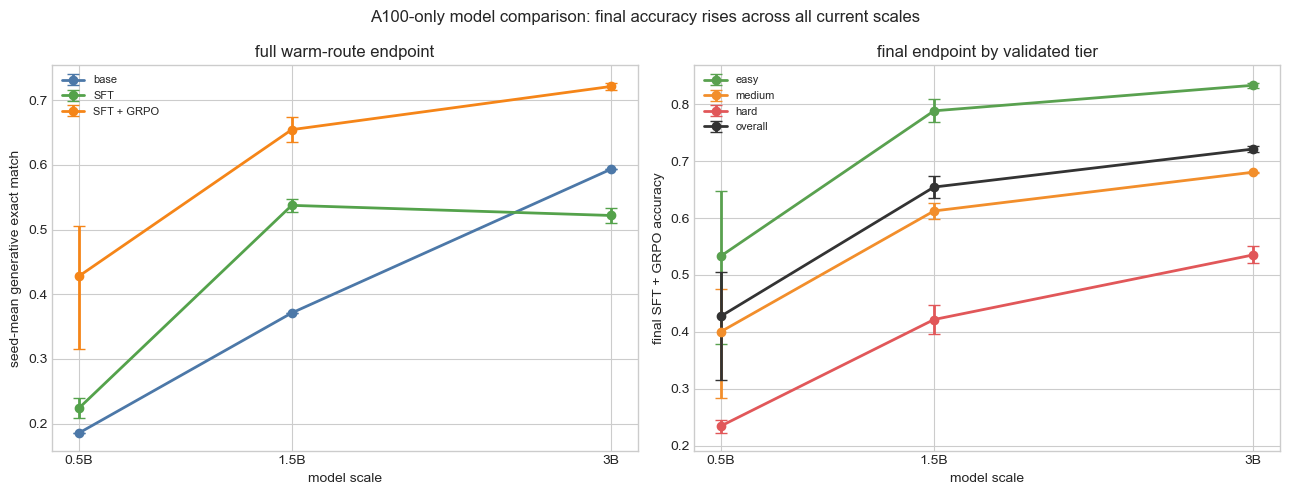

In [18]:
# plot stage accuracy and final tier accuracy on shared scale axes
x = np.array([PARAMS[scale] for scale in SCALES])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for condition in CONDITIONS:
    values = core_summary_tbl[f"{condition}_mean"].to_numpy()
    lower = values - core_summary_tbl[f"{condition}_min"].to_numpy()
    upper = core_summary_tbl[f"{condition}_max"].to_numpy() - values
    axes[0].errorbar(x, values, yerr=[lower, upper], marker="o", lw=2, capsize=4,
                     color=COLORS[condition], label=CONDITION_LABELS[condition])
axes[0].set_xticks(x)
axes[0].set_xticklabels(SCALES)
axes[0].set_xlabel("model scale")
axes[0].set_ylabel("seed-mean generative exact match")
axes[0].set_title("full warm-route endpoint")
axes[0].legend(fontsize=8)

for group in GROUPS:
    key = "grpo" if group == "overall" else f"grpo_{group}"
    values = core_summary_tbl[f"{key}_mean"].to_numpy()
    lower = values - core_summary_tbl[f"{key}_min"].to_numpy()
    upper = core_summary_tbl[f"{key}_max"].to_numpy() - values
    axes[1].errorbar(x, values, yerr=[lower, upper], marker="o", lw=2, capsize=4,
                     color=TIER_COLORS[group], label=group)
axes[1].set_xticks(x)
axes[1].set_xticklabels(SCALES)
axes[1].set_xlabel("model scale")
axes[1].set_ylabel("final SFT + GRPO accuracy")
axes[1].set_title("final endpoint by validated tier")
axes[1].legend(fontsize=8)
fig.suptitle("A100-only model comparison: final accuracy rises across all current scales")
fig.tight_layout()
save(fig, "fig01_core_scale_endpoints")
plt.show()


saved fig02_grpo_gain_by_tier


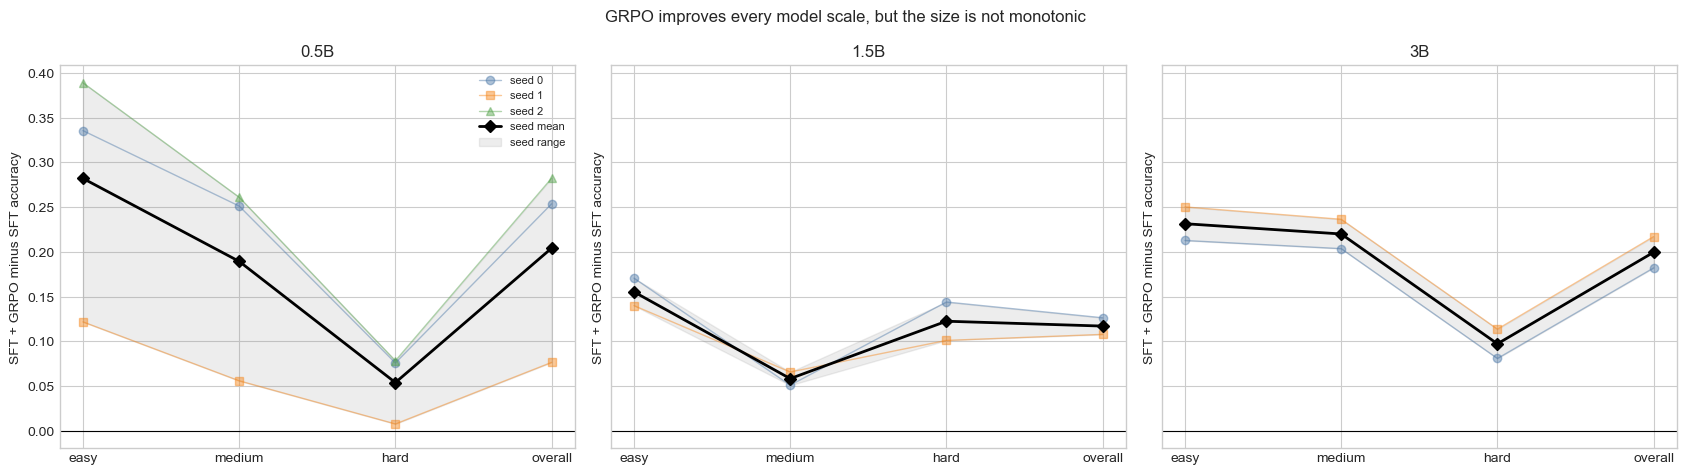

In [19]:
# keep every seed visible in the GRPO gain by tier
gain_by_scale = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
positions = np.arange(len(GROUPS))
for ax, scale in zip(axes, SCALES):
    gain_by_scale[scale] = {}
    for seed, data in CORE_DATA[scale].items():
        values = np.array([
            group_accuracy(data["gen"]["grpo"], group) - group_accuracy(data["gen"]["sft"], group)
            for group in GROUPS
        ])
        gain_by_scale[scale][seed] = values
        ax.plot(positions, values, marker=SEED_MARKERS[seed], color=SEED_COLORS[seed],
                alpha=0.45, lw=1, label=f"seed {seed}")
    matrix = np.vstack(list(gain_by_scale[scale].values()))
    ax.plot(positions, matrix.mean(axis=0), "D-", color="black", lw=2, label="seed mean")
    ax.fill_between(positions, matrix.min(axis=0), matrix.max(axis=0), color="grey", alpha=0.14,
                    label="seed range")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(positions)
    ax.set_xticklabels(GROUPS)
    ax.set_title(scale)
    ax.set_ylabel("SFT + GRPO minus SFT accuracy")
axes[0].legend(fontsize=8)
fig.suptitle("GRPO improves every model scale, but the size is not monotonic")
fig.tight_layout()
save(fig, "fig02_grpo_gain_by_tier")
plt.show()


params_b   delta   ci_lo   ci_hi
scale seed                                  
0.5B  0          0.5  0.2537  0.2288  0.2792
      1          0.5  0.0764  0.0525  0.1008
      2          0.5  0.2824  0.2574  0.3073
1.5B  0          1.5  0.1263  0.1040  0.1481
      1          1.5  0.1077  0.0881  0.1279
3B    0          3.0  0.1821  0.1592  0.2054
      1          3.0  0.2171  0.1932  0.2410

saved fig03_overall_paired_gain


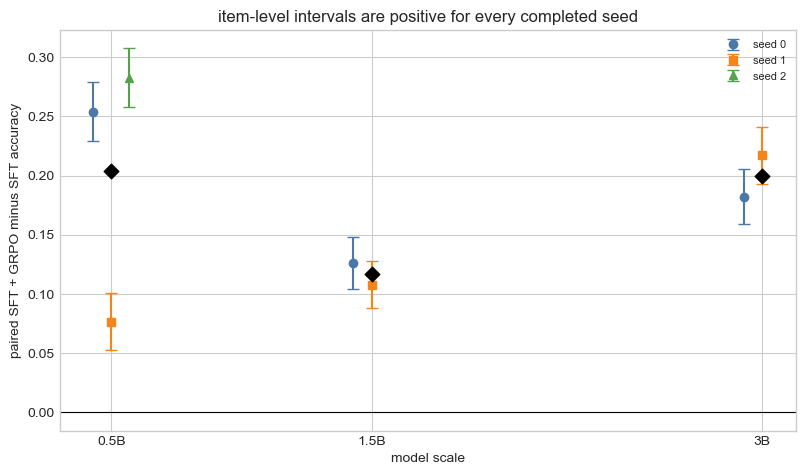

In [20]:
# compare paired overall GRPO effects without pooling different training seeds
paired_rows = []
for scale in SCALES:
    for seed, data in CORE_DATA[scale].items():
        sft_rows, grpo_rows = align_pred_rows(data["gen"]["sft"], data["gen"]["grpo"])
        sft_correct = [bool(row["correct"]) for row in sft_rows]
        grpo_correct = [bool(row["correct"]) for row in grpo_rows]
        delta, lo, hi = paired_delta_ci(sft_correct, grpo_correct, seed=1200 + int(PARAMS[scale] * 10) + seed)
        paired_rows.append({"scale": scale, "params_b": PARAMS[scale], "seed": seed,
                            "delta": delta, "ci_lo": lo, "ci_hi": hi})
paired_tbl = pd.DataFrame(paired_rows)
display(paired_tbl.set_index(["scale", "seed"]).round(4))

fig, ax = plt.subplots(figsize=(9.5, 5.2))
offsets = {0: -0.07, 1: 0.0, 2: 0.07}
for seed in (0, 1, 2):
    part = paired_tbl.query("seed == @seed")
    if part.empty:
        continue
    xp = part["params_b"].to_numpy() + offsets[seed]
    values = part["delta"].to_numpy()
    errors = [values - part["ci_lo"].to_numpy(), part["ci_hi"].to_numpy() - values]
    ax.errorbar(xp, values, yerr=errors, fmt=SEED_MARKERS[seed], capsize=4,
                color=SEED_COLORS[seed], label=f"seed {seed}")
for scale in SCALES:
    part = paired_tbl.query("scale == @scale")
    ax.scatter(PARAMS[scale], part["delta"].mean(), marker="D", s=55, color="black", zorder=4)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(SCALES)
ax.set_xlabel("model scale")
ax.set_ylabel("paired SFT + GRPO minus SFT accuracy")
ax.set_title("item-level intervals are positive for every completed seed")
ax.legend(fontsize=8)
save(fig, "fig03_overall_paired_gain")
plt.show()


## 3. Generation, probe and subject pattern


saved fig04_generation_vs_probe


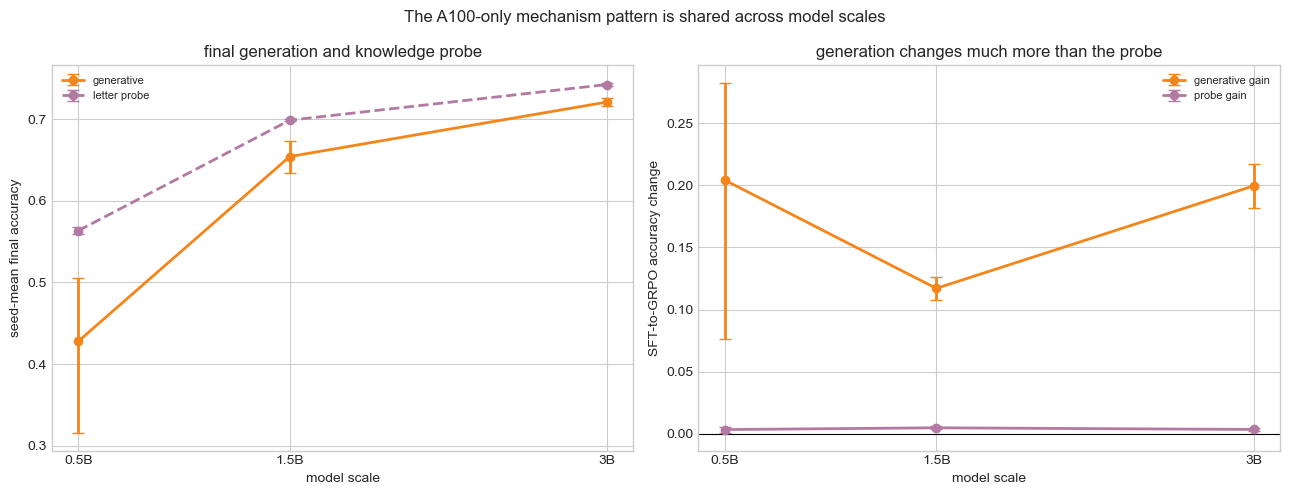

In [21]:
# compare final generation with the letter probe and their SFT-to-GRPO changes
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for key, label, color, style in [
    ("grpo", "generative", COLORS["grpo"], "-"),
    ("grpo_probe", "letter probe", COLORS["probe"], "--"),
]:
    values = core_summary_tbl[f"{key}_mean"].to_numpy()
    lower = values - core_summary_tbl[f"{key}_min"].to_numpy()
    upper = core_summary_tbl[f"{key}_max"].to_numpy() - values
    axes[0].errorbar(x, values, yerr=[lower, upper], marker="o", lw=2, ls=style,
                     capsize=4, color=color, label=label)
axes[0].set_xticks(x)
axes[0].set_xticklabels(SCALES)
axes[0].set_xlabel("model scale")
axes[0].set_ylabel("seed-mean final accuracy")
axes[0].set_title("final generation and knowledge probe")
axes[0].legend(fontsize=8)

for key, label, color in [("grpo_gain", "generative gain", COLORS["grpo"]),
                          ("probe_gain", "probe gain", COLORS["probe"])]:
    values = core_summary_tbl[f"{key}_mean"].to_numpy()
    lower = values - core_summary_tbl[f"{key}_min"].to_numpy()
    upper = core_summary_tbl[f"{key}_max"].to_numpy() - values
    axes[1].errorbar(x, values, yerr=[lower, upper], marker="o", lw=2, capsize=4,
                     color=color, label=label)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(SCALES)
axes[1].set_xlabel("model scale")
axes[1].set_ylabel("SFT-to-GRPO accuracy change")
axes[1].set_title("generation changes much more than the probe")
axes[1].legend(fontsize=8)
fig.suptitle("The A100-only mechanism pattern is shared across model scales")
fig.tight_layout()
save(fig, "fig04_generation_vs_probe")
plt.show()


saved fig05_subject_accuracy_matrix


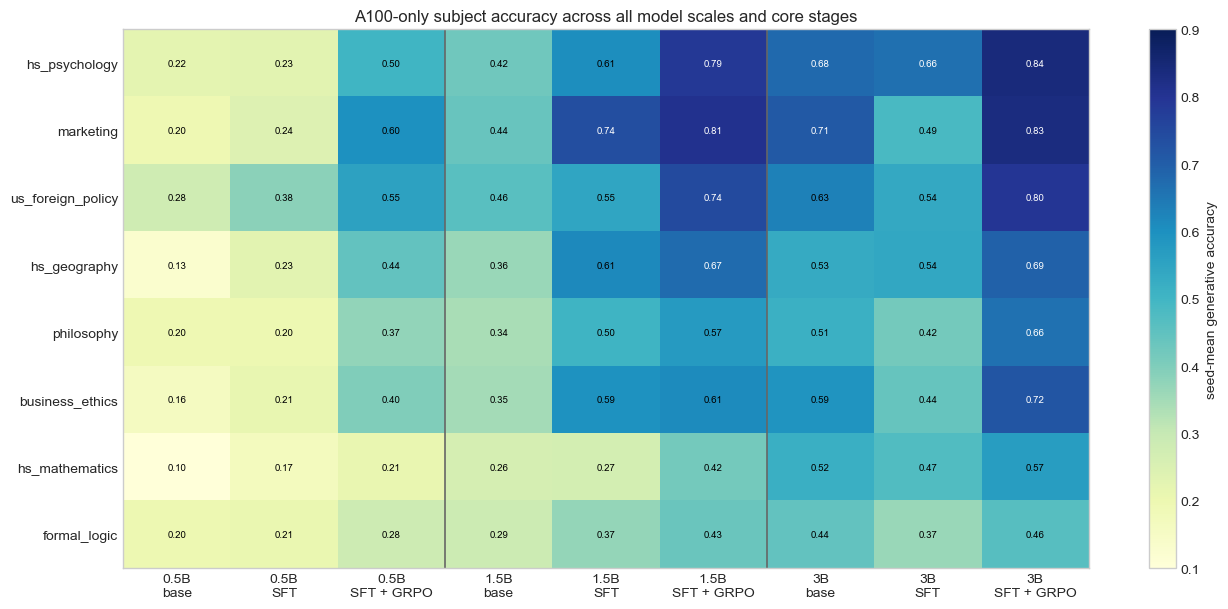

In [22]:
# plot one subject matrix with nearest interpolation to avoid heatmap seams
subjects = all_subjects()
matrix = []
column_labels = []
for scale in SCALES:
    for condition in CONDITIONS:
        seed_values = []
        for data in CORE_DATA[scale].values():
            seed_values.append([subject_accuracy(data["gen"][condition])[subject] for subject in subjects])
        matrix.append(np.mean(seed_values, axis=0))
        column_labels.append(f"{scale}\n{CONDITION_LABELS[condition]}")
matrix = np.asarray(matrix).T

fig, ax = plt.subplots(figsize=(13.5, 6.2))
image = ax.imshow(matrix, aspect="auto", vmin=0.1, vmax=0.9, cmap="YlGnBu", interpolation="nearest")
ax.set_xticks(np.arange(len(column_labels)))
ax.set_xticklabels(column_labels)
ax.set_yticks(np.arange(len(subjects)))
ax.set_yticklabels([subject.replace("high_school_", "hs_") for subject in subjects])
for row_index in range(matrix.shape[0]):
    for column_index in range(matrix.shape[1]):
        value = matrix[row_index, column_index]
        ax.text(column_index, row_index, f"{value:.2f}", ha="center", va="center",
                color=heatmap_text_color(image, value), fontsize=7)
for boundary in (2.5, 5.5):
    ax.axvline(boundary, color="#666666", lw=1.2)
ax.grid(False)
ax.set_title("A100-only subject accuracy across all model scales and core stages")
fig.colorbar(image, ax=ax, label="seed-mean generative accuracy")
fig.tight_layout()
save(fig, "fig05_subject_accuracy_matrix")
plt.show()


saved fig06_expression_gap


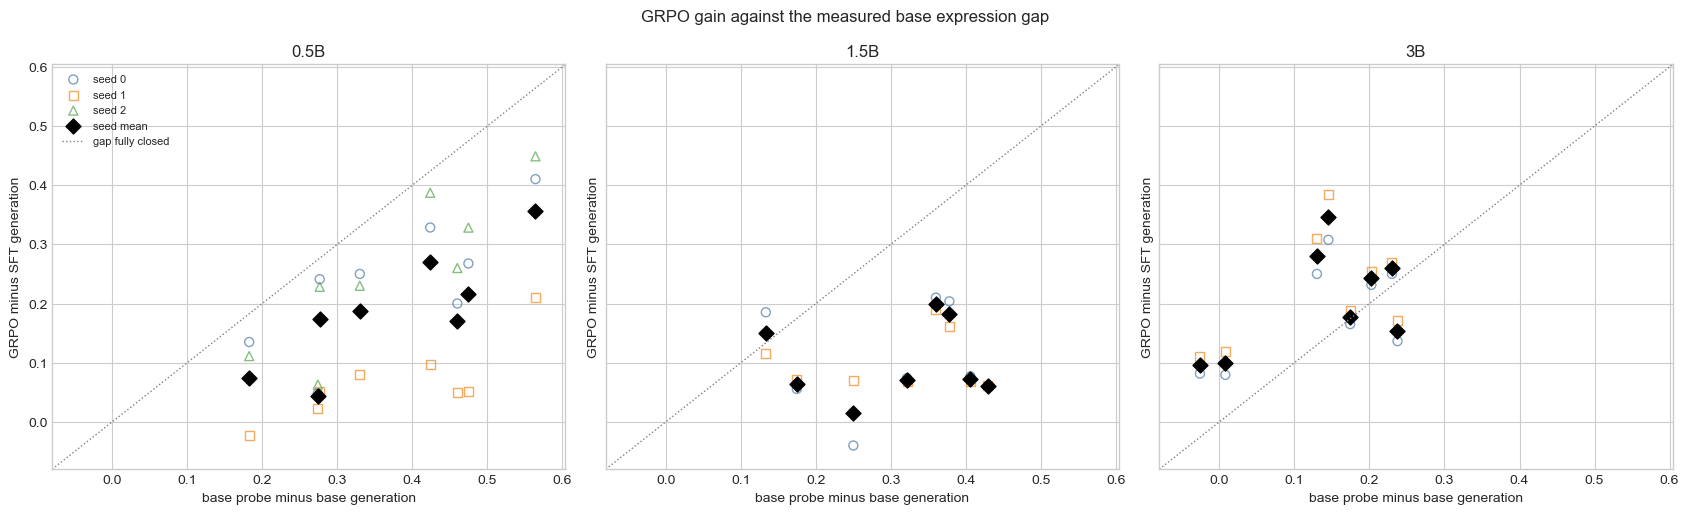

In [23]:
# compare the base expression gap with the subject-level GRPO gain
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharex=True, sharey=True)
all_values = []
for ax, scale in zip(axes, SCALES):
    first = next(iter(CORE_DATA[scale].values()))
    base_gen = subject_accuracy(first["gen"]["base"])
    base_probe = subject_accuracy(first["probe"]["base"])
    x_values = np.array([base_probe[subject] - base_gen[subject] for subject in all_subjects()])
    seed_values = []
    for seed, data in CORE_DATA[scale].items():
        sft = subject_accuracy(data["gen"]["sft"])
        grpo = subject_accuracy(data["gen"]["grpo"])
        y_values = np.array([grpo[subject] - sft[subject] for subject in all_subjects()])
        seed_values.append(y_values)
        ax.scatter(x_values, y_values, marker=SEED_MARKERS[seed], s=42, facecolors="none",
                   edgecolors=SEED_COLORS[seed], alpha=0.7, label=f"seed {seed}")
        all_values.extend(x_values.tolist() + y_values.tolist())
    ax.scatter(x_values, np.vstack(seed_values).mean(axis=0), marker="D", s=58,
               color="black", label="seed mean")
    ax.set_title(scale)
    ax.set_xlabel("base probe minus base generation")
    ax.set_ylabel("GRPO minus SFT generation")
limit_low = min(all_values) - 0.04
limit_high = max(all_values) + 0.04
for ax in axes:
    ax.plot([limit_low, limit_high], [limit_low, limit_high], ls=":", color="grey", lw=1,
            label="gap fully closed")
    ax.set_xlim(limit_low, limit_high)
    ax.set_ylim(limit_low, limit_high)
axes[0].legend(fontsize=8)
fig.suptitle("GRPO gain against the measured base expression gap")
fig.tight_layout()
save(fig, "fig06_expression_gap")
plt.show()


## 4. Available A100 method controls


accuracy
scale method      seed          
0.5B  base GRPO   0       0.3992
      warm GRPO   0       0.4623
                  1       0.3153
                  2       0.5058
      base MC-SFT 0       0.5382
                  1       0.5334
                  2       0.5303
      warm MC-SFT 0       0.5345
                  1       0.5318
                  2       0.5340
1.5B  warm GRPO   0       0.6741
                  1       0.6348
3B    base GRPO   0       0.6768
      warm GRPO   0       0.7160
                  1       0.7266
      base MC-SFT 0       0.7325
                  1       0.7256
                  2       0.7346
      warm MC-SFT 0       0.7325
                  1       0.7394
                  2       0.7394

n_seeds    mean     min     max
scale method                                      
0.5B  base GRPO          1  0.3992  0.3992  0.3992
      warm GRPO          3  0.4278  0.3153  0.5058
      base MC-SFT        3  0.5340  0.5303  0.5382
      warm MC-SFT        3  0.5334  0.5318  0.5345
1.5B  base GRPO          0     NaN     NaN     NaN
      warm GRPO          2  0.6545  0.6348  0.6741
      base MC-SFT        0     NaN     NaN     NaN
      warm MC-SFT        0     NaN     NaN     NaN
3B    base GRPO          1  0.6768  0.6768  0.6768
      warm GRPO          2  0.7213  0.7160  0.7266
      base MC-SFT        3  0.7309  0.7256  0.7346
      warm MC-SFT        3  0.7371  0.7325  0.7394

saved fig07_available_method_endpoints


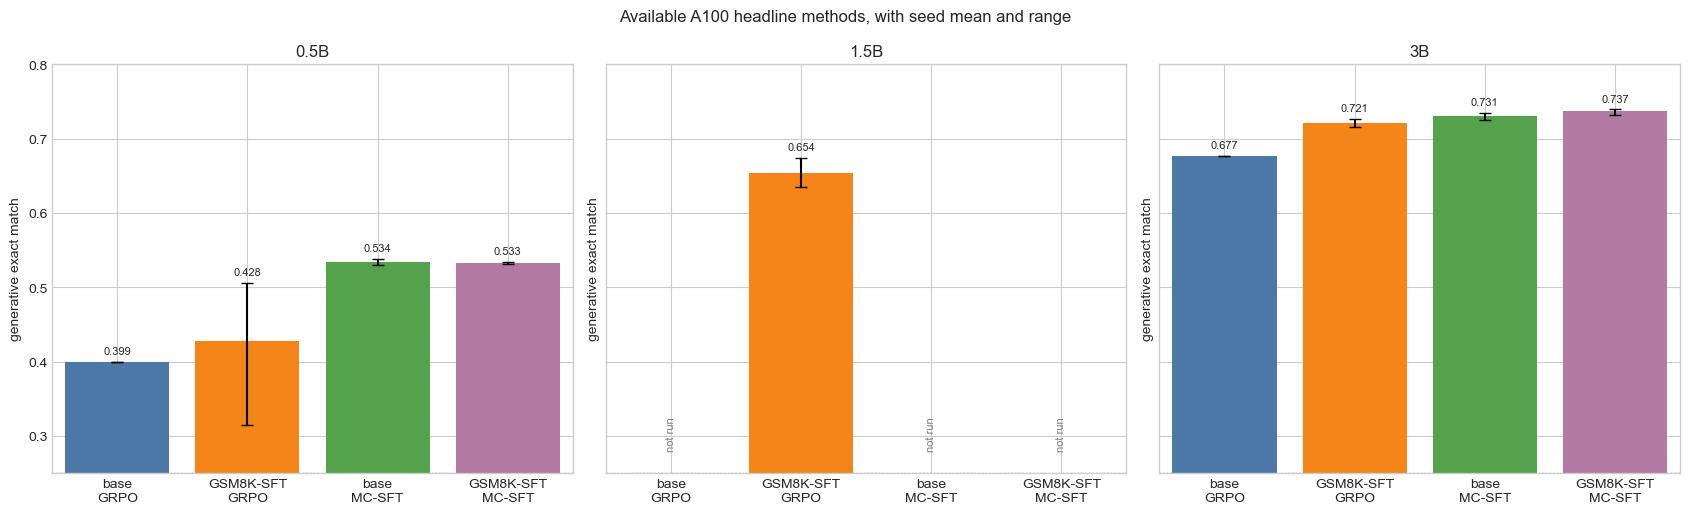

In [24]:
# compare every available headline method without inventing missing 1.5B controls
METHODS = ["base GRPO", "warm GRPO", "base MC-SFT", "warm MC-SFT"]
METHOD_LABELS = ["base\nGRPO", "GSM8K-SFT\nGRPO", "base\nMC-SFT", "GSM8K-SFT\nMC-SFT"]
METHOD_COLORS = {"base GRPO": "#4C78A8", "warm GRPO": "#F58518",
                 "base MC-SFT": "#54A24B", "warm MC-SFT": "#B279A2"}
control_rows = []
for scale in SCALES:
    for method, seed_runs in CONTROL_DATA[scale].items():
        for seed, data in seed_runs.items():
            control_rows.append({"scale": scale, "method": method, "seed": seed, "accuracy": accuracy(data)})
control_seed_tbl = pd.DataFrame(control_rows)

control_summary_rows = []
for scale in SCALES:
    for method in METHODS:
        part = control_seed_tbl.query("scale == @scale and method == @method")
        control_summary_rows.append({
            "scale": scale,
            "method": method,
            "n_seeds": len(part),
            "mean": part["accuracy"].mean() if len(part) else np.nan,
            "min": part["accuracy"].min() if len(part) else np.nan,
            "max": part["accuracy"].max() if len(part) else np.nan,
        })
control_summary_tbl = pd.DataFrame(control_summary_rows)
display(control_seed_tbl.set_index(["scale", "method", "seed"]).round(4))
display(control_summary_tbl.set_index(["scale", "method"]).round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True)
method_positions = np.arange(len(METHODS))
for ax, scale in zip(axes, SCALES):
    part = control_summary_tbl.query("scale == @scale").set_index("method").loc[METHODS]
    for position, method in enumerate(METHODS):
        row = part.loc[method]
        if np.isnan(row["mean"]):
            ax.text(position, 0.28, "not run", ha="center", va="bottom", rotation=90,
                    color="grey", fontsize=8)
            continue
        lower = row["mean"] - row["min"]
        upper = row["max"] - row["mean"]
        ax.bar(position, row["mean"], color=METHOD_COLORS[method],
               yerr=np.array([[lower], [upper]]), capsize=4)
        ax.annotate(f"{row['mean']:.3f}", (position, row["mean"] + upper),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=8)
    ax.axhline(0.25, color="grey", ls=":", lw=1)
    ax.set_xlim(-0.5, len(method_positions) - 0.5)
    ax.set_xticks(method_positions)
    ax.set_xticklabels(METHOD_LABELS)
    ax.set_ylim(0.25, 0.8)
    ax.set_title(scale)
    ax.set_ylabel("generative exact match")
fig.suptitle("Available A100 headline methods, with seed mean and range")
fig.tight_layout()
save(fig, "fig07_available_method_endpoints")
plt.show()


delta   ci_lo   ci_hi
scale method                        
0.5B  GRPO    0.0632  0.0366  0.0892
      MC-SFT -0.0037 -0.0175  0.0101
3B    GRPO    0.0393  0.0191  0.0600
      MC-SFT  0.0000 -0.0122  0.0122

saved fig08_seed0_preparation_effect


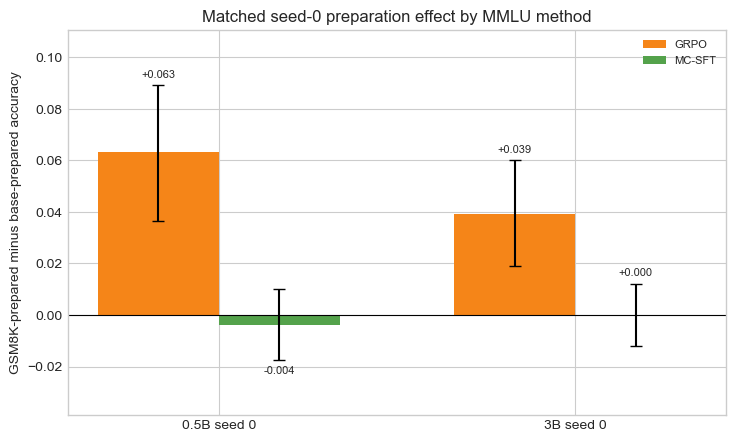

In [25]:
# keep the matched seed-0 preparation effects separate from procedure means
prep_rows = []
for scale in ("0.5B", "3B"):
    comparisons = {
        "GRPO": (CONTROL_DATA[scale]["base GRPO"][0], CONTROL_DATA[scale]["warm GRPO"][0]),
        "MC-SFT": (CONTROL_DATA[scale]["base MC-SFT"][0], CONTROL_DATA[scale]["warm MC-SFT"][0]),
    }
    for method, (base_rows, warm_rows) in comparisons.items():
        base_rows, warm_rows = align_pred_rows(base_rows, warm_rows)
        base_correct = [bool(row["correct"]) for row in base_rows]
        warm_correct = [bool(row["correct"]) for row in warm_rows]
        delta, lo, hi = paired_delta_ci(base_correct, warm_correct,
                                        seed=1400 + int(PARAMS[scale] * 10) + (method == "MC-SFT"))
        prep_rows.append({"scale": scale, "method": method, "delta": delta, "ci_lo": lo, "ci_hi": hi})
prep_tbl = pd.DataFrame(prep_rows)
display(prep_tbl.set_index(["scale", "method"]).round(4))

fig, ax = plt.subplots(figsize=(8.5, 5))
base_x = np.arange(2)
width = 0.34
for index, method in enumerate(("GRPO", "MC-SFT")):
    part = prep_tbl.query("method == @method").set_index("scale").loc[["0.5B", "3B"]]
    values = part["delta"].to_numpy()
    errors = [values - part["ci_lo"].to_numpy(), part["ci_hi"].to_numpy() - values]
    bars = ax.bar(base_x + (index - 0.5) * width, values, width, yerr=errors, capsize=4,
                  color=COLORS["grpo"] if method == "GRPO" else COLORS["sft"], label=method)
    labels = [f"{value:+.3f}" for value in values]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=8)
ax.margins(y=0.2)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(base_x)
ax.set_xticklabels(["0.5B seed 0", "3B seed 0"])
ax.set_ylabel("GSM8K-prepared minus base-prepared accuracy")
ax.set_title("Matched seed-0 preparation effect by MMLU method")
ax.legend(fontsize=8)
save(fig, "fig08_seed0_preparation_effect")
plt.show()


## 5. Tier robustness and A100 compute context


In [26]:
# check whether the proposal tier grouping changes the cross-scale result
robustness_rows = []
for scale in SCALES:
    for seed, data in CORE_DATA[scale].items():
        for grouping, tiers in (("validated", VALIDATED_TIERS), ("proposal", TIERS_PROPOSAL)):
            for tier in TIERS:
                delta = (group_accuracy(data["gen"]["grpo"], tier, tiers) -
                         group_accuracy(data["gen"]["sft"], tier, tiers))
                robustness_rows.append({"scale": scale, "seed": seed, "grouping": grouping,
                                        "tier": tier, "grpo_gain": delta})
robustness_tbl = pd.DataFrame(robustness_rows)
robustness_summary = robustness_tbl.groupby(["scale", "grouping", "tier"])["grpo_gain"].mean().unstack("grouping")
robustness_summary["validated minus proposal"] = robustness_summary["validated"] - robustness_summary["proposal"]
display(robustness_summary.round(4))
print("largest absolute tier-grouping change:",
      f"{robustness_summary['validated minus proposal'].abs().max():.3f}")


grouping      proposal  validated  validated minus proposal
scale tier                                                 
0.5B  easy      0.2840     0.2821                   -0.0019
      hard      0.0539     0.0539                    0.0000
      medium    0.1866     0.1894                    0.0027
1.5B  easy      0.1342     0.1553                    0.0210
      hard      0.1225     0.1225                    0.0000
      medium    0.0887     0.0583                   -0.0304
3B    easy      0.2338     0.2315                   -0.0023
      hard      0.0972     0.0972                    0.0000
      medium    0.2167     0.2200                    0.0033

largest absolute tier-grouping change: 0.030


params_b                    GPU  training_hours  \
scale seed                                                    
0.5B  1          0.5  NVIDIA A100-SXM4-40GB           4.532   
      2          0.5  NVIDIA A100-SXM4-40GB           3.863   
1.5B  0          1.5  NVIDIA A100-SXM4-80GB           3.277   
      1          1.5  NVIDIA A100-SXM4-80GB           3.211   
3B    0          3.0  NVIDIA A100-SXM4-80GB           3.943   
      1          3.0  NVIDIA A100-SXM4-80GB           3.977   

            recorded_stage_hours  peak_vram_gb  
scale seed                                      
0.5B  1                    6.563        21.644  
      2                    5.598        21.644  
1.5B  0                    5.602        35.134  
      1                    5.022        35.134  
3B    0                    6.469        50.403  
      1                    6.600        50.106

saved fig09_a100_training_time


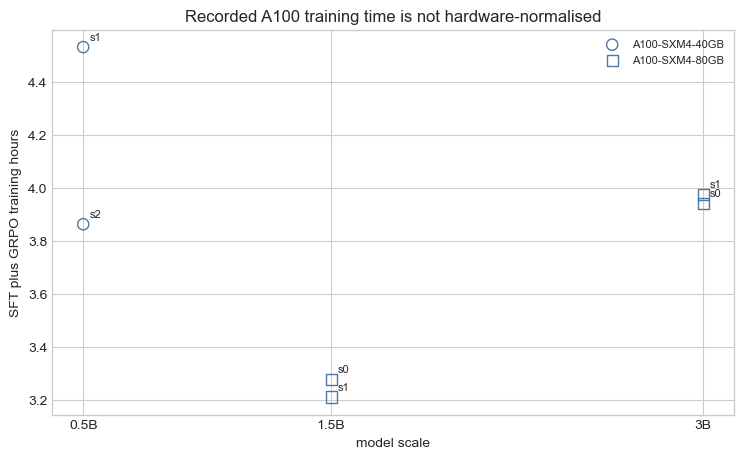

006 seed 0 is omitted from timing because its resumed manifest does not contain both training stages


In [27]:
# compare available training time while keeping the A100 memory variant visible
compute_rows = []
for scale in SCALES:
    for seed, data in CORE_DATA[scale].items():
        timings = data["manifest"].get("timings_sec", {})
        if "sft_train" not in timings or "grpo_train" not in timings:
            continue
        compute_rows.append({
            "scale": scale,
            "params_b": PARAMS[scale],
            "seed": seed,
            "GPU": data["manifest"]["gpu"]["device"],
            "training_hours": (timings["sft_train"] + timings["grpo_train"]) / 3600,
            "recorded_stage_hours": sum(timings.values()) / 3600,
            "peak_vram_gb": data["manifest"]["gpu"]["peak_vram_gb"],
        })
compute_tbl = pd.DataFrame(compute_rows)
display(compute_tbl.set_index(["scale", "seed"]).round(3))

fig, ax = plt.subplots(figsize=(8.8, 5))
gpu_markers = {"NVIDIA A100-SXM4-40GB": "o", "NVIDIA A100-SXM4-80GB": "s"}
for gpu, marker in gpu_markers.items():
    part = compute_tbl.query("GPU == @gpu")
    ax.scatter(part["params_b"], part["training_hours"], marker=marker, s=65,
               facecolors="none", edgecolors=COLORS["base"], label=gpu.replace("NVIDIA ", ""))
for _, row in compute_tbl.iterrows():
    ax.annotate(f"s{row['seed']}", (row["params_b"], row["training_hours"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(SCALES)
ax.set_xlabel("model scale")
ax.set_ylabel("SFT plus GRPO training hours")
ax.set_title("Recorded A100 training time is not hardware-normalised")
ax.legend(fontsize=8)
save(fig, "fig09_a100_training_time")
plt.show()
print("006 seed 0 is omitted from timing because its resumed manifest does not contain both training stages")


## 6. Numeric tables


In [28]:
# keep the exact tier endpoints and gains behind the figures
tier_rows = []
for scale in SCALES:
    for seed, data in CORE_DATA[scale].items():
        for group in GROUPS:
            tier_rows.append({
                "scale": scale,
                "seed": seed,
                "group": group,
                "base": group_accuracy(data["gen"]["base"], group),
                "SFT": group_accuracy(data["gen"]["sft"], group),
                "SFT + GRPO": group_accuracy(data["gen"]["grpo"], group),
                "GRPO gain": (group_accuracy(data["gen"]["grpo"], group) -
                              group_accuracy(data["gen"]["sft"], group)),
            })
tier_tbl = pd.DataFrame(tier_rows)
display(tier_tbl.set_index(["scale", "seed", "group"]).round(4))

print("subject matrix values")
subject_matrix_tbl = pd.DataFrame(matrix, index=subjects, columns=column_labels)
display(subject_matrix_tbl.round(4))


base     SFT  SFT + GRPO  GRPO gain
scale seed group                                         
0.5B  0    easy     0.2218  0.2389      0.5745     0.3356
           medium   0.1675  0.1905      0.4417     0.2512
           hard     0.1313  0.1692      0.2449     0.0758
           overall  0.1852  0.2086      0.4623     0.2537
      1    easy     0.2218  0.2571      0.3788     0.1217
           medium   0.1675  0.2282      0.2841     0.0558
           hard     0.1313  0.2146      0.2222     0.0076
           overall  0.1852  0.2389      0.3153     0.0764
      2    easy     0.2218  0.2582      0.6473     0.3891
           medium   0.1675  0.2151      0.4762     0.2611
           hard     0.1313  0.1591      0.2374     0.0783
           overall  0.1852  0.2235      0.5058     0.2824
1.5B  0    easy     0.4312  0.6382      0.8089     0.1706
           medium   0.3498  0.5764      0.6273     0.0509
           hard     0.2702  0.3030      0.4470     0.1439
           overall  0.3710  0.5478      0.6741     0.1263
      1    easy     0.4312  0.6280      0.7679     0.1399
           medium   0.3498  0.5320      0.5977     0.0657
           hard     0.2702  0.2955      0.3965     0.1010
           overall  0.3710  0.5271      0.6348     0.1077
3B    0    easy     0.6803  0.6166      0.8294     0.2127
           medium   0.5320  0.4762      0.6798     0.2036
           hard     0.4949  0.4394      0.5202     0.0808
           overall  0.5934  0.5340      0.7160     0.1821
      1    easy     0.6803  0.5870      0.8373     0.2503
           medium   0.5320  0.4450      0.6814     0.2365
           hard     0.4949  0.4369      0.5505     0.1136
           overall  0.5934  0.5096      0.7266     0.2171

subject matrix values


,0.5B\nbase,0.5B\nSFT,0.5B\nSFT + GRPO,1.5B\nbase,1.5B\nSFT,1.5B\nSFT + GRPO,3B\nbase,3B\nSFT,3B\nSFT + GRPO
high_school_psychology,0.2220,0.2306,0.5015,0.4239,0.6055,0.7881,0.6771,0.6633,0.8404
marketing,0.1966,0.2436,0.5997,0.4359,0.7350,0.8077,0.7094,0.4872,0.8333
us_foreign_policy,0.2800,0.3833,0.5533,0.4600,0.5450,0.7450,0.6300,0.5350,0.7950
high_school_geography,0.1263,0.2290,0.4444,0.3636,0.6136,0.6742,0.5303,0.5379,0.6919
philosophy,0.1961,0.1994,0.3730,0.3408,0.5032,0.5740,0.5145,0.4180,0.6608
business_ethics,0.1600,0.2133,0.4000,0.3500,0.5950,0.6100,0.5900,0.4400,0.7200
high_school_mathematics,0.1000,0.1679,0.2123,0.2630,0.2667,0.4167,0.5185,0.4722,0.5685
formal_logic,0.1984,0.2090,0.2831,0.2857,0.3690,0.4325,0.4444,0.3651,0.4643


## Cross-referenced conclusion

The clean A100-only scale comparison is experiments 006, 009 and 003. The mean final
SFT + GRPO accuracy rises from 42.8% at 0.5B to 65.4% at 1.5B and 72.1% at 3B.
The same ordering appears in every validated tier: easy is 52.9%, 78.8%, 82.9%;
medium is 40.8%, 61.2%, 68.6%; and hard is 23.5%, 42.2%, 53.5%.

The incremental GRPO effect is not a simple scale curve. Mean GRPO gain over SFT is
20.4 points at 0.5B, 11.7 at 1.5B and 20.0 at 3B. Every completed seed is positive,
but the 0.5B range is much wider. The letter-probe gain stays below half a point at
all three scales, while generative accuracy changes much more. This keeps the main
interpretation around elicitation, reasoning behaviour and output control rather
than a large change in the measured stored-answer probe.

The A100 method controls also matter. At 0.5B, matched-exposure MC-SFT reaches about
53.4%, above the 42.8% warm-GRPO mean. At 3B, MC-SFT reaches 73.1% from base and 73.7%
after GSM8K-SFT, close to the 72.1% warm-GRPO mean. GRPO therefore works below 7B in
this protocol, but it is not the only method that improves these models and it is
not the strongest endpoint in every available comparison.

The control matrix is still incomplete because 1.5B currently has only the warm
SFT-to-GRPO route. Base-GRPO, base MC-SFT and warm MC-SFT were not run at 1.5B. Seed
counts also differ, and A100 40GB and 80GB are both present. The accuracy comparison
is A100-only and protocol-matched for the core route, but the runtime plot should not
be treated as a hardware-normalised scaling law.
